# Airbnb Paris Listings : Exploratory Data Analysis and K-means clustering

The goal of this project is to conduct a global exploratory analysis of an Airbnb dataset
in order to understand the main characteristics of the listings.
We first aim to identify the most important variables and general trends in the data.

In a second step, we focus more specifically on the price of listings and its relationship
with location. In particular we study how prices vary across geographical areas and
use clustering techniques to identify zones with similar price levels.


In [1]:
"We start by importing the librairies we are going to use"
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## 1) Loading the dataset

We start by loading the CSV file and taking a first look:
- number of rows and columns
- column names and types
- a few example rows

This helps us understand what kind of cleaning will be necessary.


In [2]:
df = pd.read_csv("Listings.csv",encoding="latin1")

print("Shape:", df.shape)
display(df.head(5))
display(df.tail(3))


/tmp/ipython-input-981898167.py:1: DtypeWarning: Columns (5,13) have mixed types. Specify dtype option on import or set low_memory=False.
  df = pd.read_csv("Listings.csv",encoding="latin1")


Shape: (279712, 33)


,listing_id,name,host_id,host_since,host_location,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_total_listings_count,...,minimum_nights,maximum_nights,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable
0,281420,"Beautiful Flat in le Village Montmartre, Paris",1466919,2011-12-03,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
1,3705183,39 mÃÂ² Paris (Sacre CÃ âur),10328771,2013-11-29,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
2,4082273,"Lovely apartment with Terrace, 60m2",19252768,2014-07-31,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
3,4797344,Cosy studio (close to Eiffel tower),10668311,2013-12-17,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
4,4823489,Close to Eiffel Tower - Beautiful flat : 2 rooms,24837558,2014-12-14,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,2,1125,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f


,listing_id,name,host_id,host_since,host_location,host_response_time,host_response_rate,host_acceptance_rate,host_is_superhost,host_total_listings_count,...,minimum_nights,maximum_nights,review_scores_rating,review_scores_accuracy,review_scores_cleanliness,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable
279709,38683356,Nice and cosy mini-appartement in Paris,2238502,2012-04-27,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,6,30,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
279710,39659000,Charming apartment near Rue Saint Maur / Oberk...,38633695,2015-07-16,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,3,18,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f
279711,40219504,Cosy apartment with view on Canal St Martin,6955618,2013-06-17,"Paris, Ile-de-France, France",NaN,NaN,NaN,f,1.0,...,2,4,100.0,10.0,10.0,10.0,10.0,10.0,10.0,f


## 2) Dataset structure and missing values

We check:
- data types (numeric vs categorical)
- missing values (NaNs)
- a small summary table to see which columns might need cleaning

In [3]:
df.info()
missing = df.isna().sum().sort_values(ascending=False)

print("The 15 columns with the most missing values")
print(missing.head(15))


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 279712 entries, 0 to 279711
Data columns (total 33 columns):
 #   Column                       Non-Null Count   Dtype  
---  ------                       --------------   -----  
 0   listing_id                   279712 non-null  int64  
 1   name                         279537 non-null  object 
 2   host_id                      279712 non-null  int64  
 3   host_since                   279547 non-null  object 
 4   host_location                278872 non-null  object 
 5   host_response_time           150930 non-null  object 
 6   host_response_rate           150930 non-null  float64
 7   host_acceptance_rate         166625 non-null  float64
 8   host_is_superhost            279547 non-null  object 
 9   host_total_listings_count    279547 non-null  float64
 10  host_has_profile_pic         279547 non-null  object 
 11  host_identity_verified       279547 non-null  object 
 12  neighbourhood                279712 non-null  object 
 13 

## 3) Data cleaning

Before starting the analysis we clean the dataset to keep only reliable observations.

The cleaning steps are the following:
- we keep only a subset of relevant variables for the study
- we remove rows with missing values in essential variables (latitude, longitude and price)
- for the other numerical variables missing values are replaced by the median
- if some missing values are still present after this step the remaining rows are removed

In [4]:
# --- Select relevant columns ---
candidate_cols = [
    "neighbourhood", "city",
    "property_type", "room_type", "instant_bookable",
    "latitude", "longitude", "price",
    "accommodates", "bedrooms",
    "minimum_nights", "review_scores_rating","host_is_superhost","host_since"
]

available_cols = [c for c in candidate_cols if c in df.columns]
df_small = df[available_cols].copy()

# --- Basic cleaning ---

# Essential columns for the analysis
essential = ["latitude", "longitude", "price"]

# Drop rows with missing values in essential columns
df_clean = df_small.dropna(subset=essential).copy()

# Impute missing values in other numerical columns using the median
to_impute = [
    "accommodates",
    "bedrooms",
    "minimum_nights",
    "review_scores_rating"
]

for col in to_impute:
    if col in df_clean.columns:
        df_clean[col] = df_clean[col].fillna(df_clean[col].median())

# If there are still missing values, drop the remaining rows
df_clean = df_clean.dropna()

print(df_clean.head())

       neighbourhood   city     property_type     room_type instant_bookable  \
0  Buttes-Montmartre  Paris  Entire apartment  Entire place                f   
1  Buttes-Montmartre  Paris  Entire apartment  Entire place                f   
2             Elysee  Paris  Entire apartment  Entire place                f   
3          Vaugirard  Paris  Entire apartment  Entire place                f   
4              Passy  Paris  Entire apartment  Entire place                f   

   latitude  longitude  price  accommodates  bedrooms  minimum_nights  \
0  48.88668    2.33343     53             2       1.0               2   
1  48.88617    2.34515    120             2       1.0               2   
2  48.88112    2.31712     89             2       1.0               2   
3  48.84571    2.30584     58             2       1.0               2   
4  48.85500    2.26979     60             2       1.0               2   

   review_scores_rating host_is_superhost  host_since  
0                 100.0 

## 4) Exploratory Data Analysis

In this section, we explore the main variables:
- distributions of numerical variables
- comparisons by categories
- simple relationships between variables

### 4.1 Global analysis

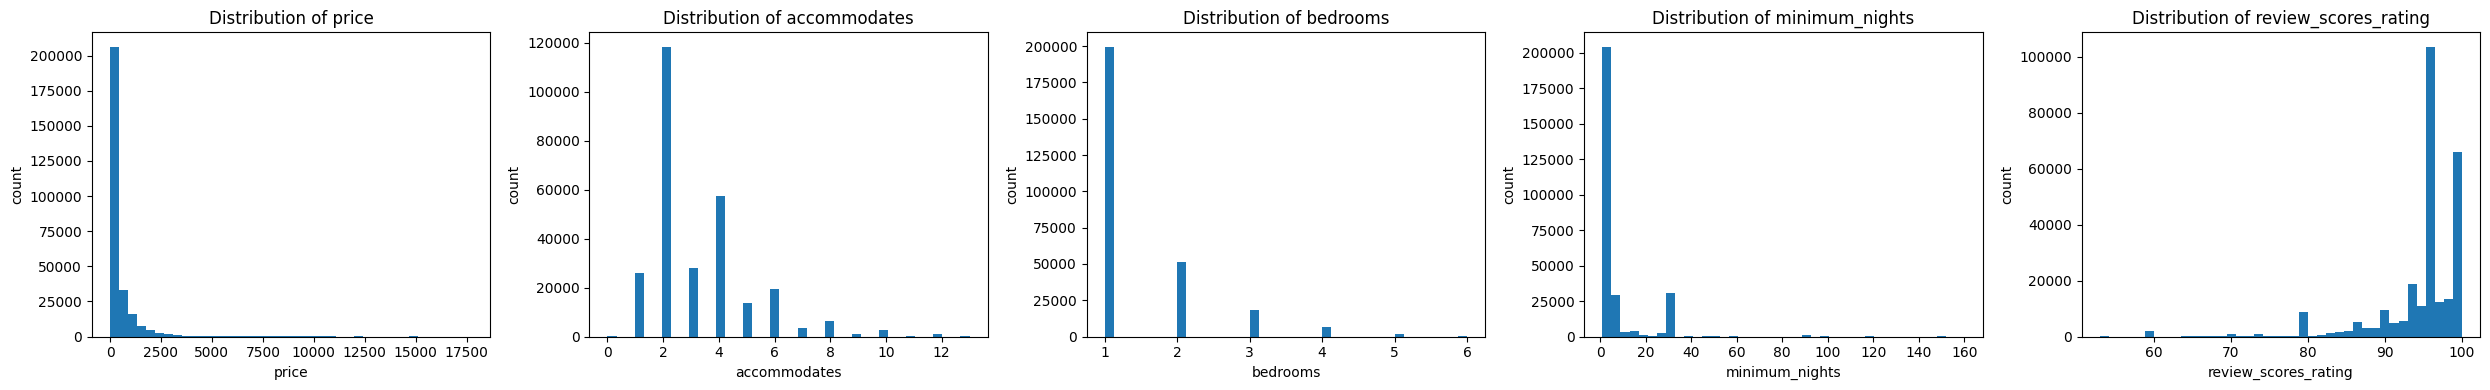

In [5]:
num_cols = ["price", "accommodates", "bedrooms", "minimum_nights", "review_scores_rating"]
num_cols = [c for c in num_cols if c in df_clean.columns]

fig, axes = plt.subplots(1, len(num_cols), figsize=(5 * len(num_cols), 4))

if len(num_cols) == 1:
    axes = [axes]

for ax, col in zip(axes, num_cols):
    data = df_clean[col]

    mean = data.mean()
    std = data.std()

    # Focus on central values
    lower = mean - 5 * std
    upper = mean + 5 * std

    ax.hist(data[(data >= lower) & (data <= upper)], bins=40)
    ax.set_title(f"Distribution of {col}")
    ax.set_xlabel(col)
    ax.set_ylabel("count")

plt.tight_layout()
plt.show()

### Analysis of the distributions

The histogram of **price** shows a very right-skewed distribution.
Most listings have relatively low prices, while a small number of listings are extremely expensive.
This indicates the presence of outliers and suggests that price is not uniformly distributed.

The distribution of **accommodates** shows that most listings can host between 1 and 4 people.
Larger accommodations exist but are much less frequent.

Similarly, the distribution of **bedrooms** is highly concentrated around small values.
Most listings have 1 or 2 bedrooms while listings with many bedrooms are rare.
This is consistent with the accommodates variable and confirms that large properties are uncommon.

The **minimum_nights** variable is also strongly skewed.
Most listings allow very short stays, often only a few nights, while a small number of listings
require very long minimum stays.
This indicates heterogeneous booking policies across hosts.

Finally the distribution of **review_scores_rating** is concentrated at high values.
Most listings have ratings close to 90 or above showing that Airbnb ratings tend to be positively biased
and that very low ratings are rare.

Overall these distributions highlight strong asymmetries in the data and suggest that some variables,
especially price, contain extreme values that need to be interpreted carefully in further analysis.


### 4.2 Host characteristics analysis


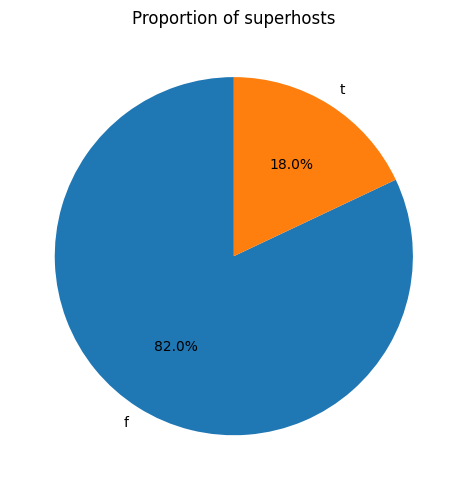

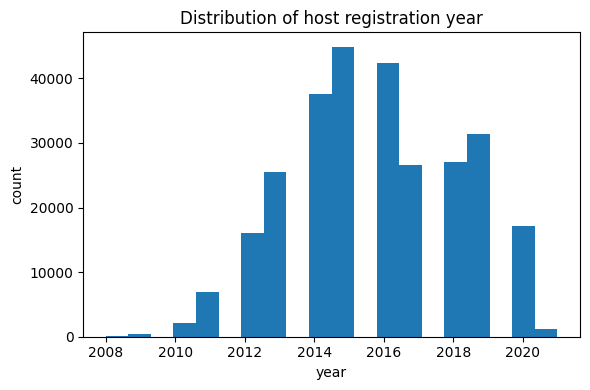

In [6]:
# Host characteristics analysis

# Pie chart: Superhost status
superhost_counts = df["host_is_superhost"].value_counts()

plt.figure(figsize=(5, 5))
plt.pie(
    superhost_counts,
    labels=superhost_counts.index,
    autopct="%1.1f%%",
    startangle=90
)
plt.title("Proportion of superhosts")
plt.tight_layout()
plt.show()


# Histogram: Host since (year)
host_since = pd.to_datetime(df["host_since"], errors="coerce")

plt.figure(figsize=(6, 4))
plt.hist(host_since.dt.year.dropna(), bins=20)
plt.title("Distribution of host registration year")
plt.xlabel("year")
plt.ylabel("count")
plt.tight_layout()
plt.show()

### Host characteristics

The pie chart shows that only a minority of hosts are superhosts.
Approximately 18% of the listings are managed by superhosts while the majority
of hosts do not have this status.

The histogram of host registration year indicates that most hosts joined the
platform after 2012 with a peak around the mid-2010s.
This suggests a rapid growth of the platform during this period followed by
a stabilization in more recent years.

These results show that most listings are managed by relatively recent
hosts and that superhost status is held by a limited share of hosts.

### 4.3 Price by category

A common question is: does price change depending on the type of accommodation?

That's why we compare prices by room type.

We use boxplots because as shown in the previous analysis it seems that some of our variables have outliers.


/tmp/ipython-input-2711891709.py:9: MatplotlibDeprecationWarning: The 'labels' parameter of boxplot() has been renamed 'tick_labels' since Matplotlib 3.9; support for the old name will be dropped in 3.11.
  plt.boxplot(data_by_cat, labels=categories, showfliers=False)


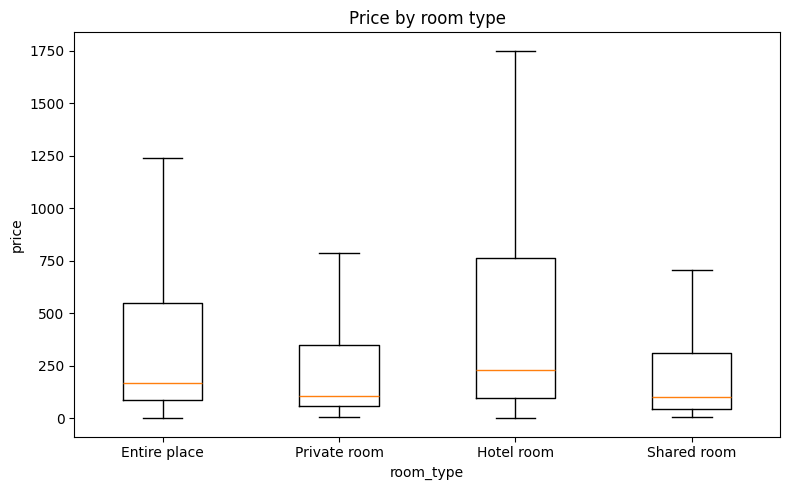

In [7]:

categories = df_clean["room_type"].unique()

data_by_cat = []
for cat in categories:
    prices_cat = df_clean[df_clean["room_type"] == cat]["price"]
    data_by_cat.append(prices_cat)

plt.figure(figsize=(8, 5))
plt.boxplot(data_by_cat, labels=categories, showfliers=False)
plt.title("Price by room type")
plt.xlabel("room_type")
plt.ylabel("price")
plt.tight_layout()
plt.show()


The boxplots highlight clear price differences across room types.
Entire places and hotel rooms have higher median prices and a wider spread
while private rooms are generally cheaper.
Shared rooms are the least expensive option.

These differences suggest that room type plays an important role in price formation
and will be taken into account when interpreting the results of the clustering analysis for example.


### 4.4 Simple relationships (scatter plots)

We explore simple relationships such as:
- price vs accommodates
- price vs review score

These plots help us understand which variables may be related.


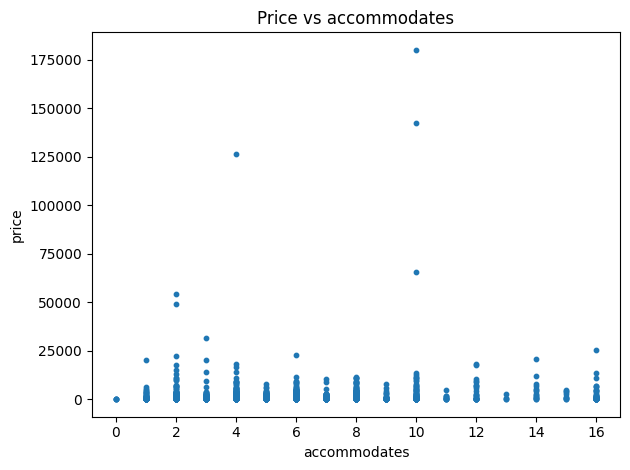

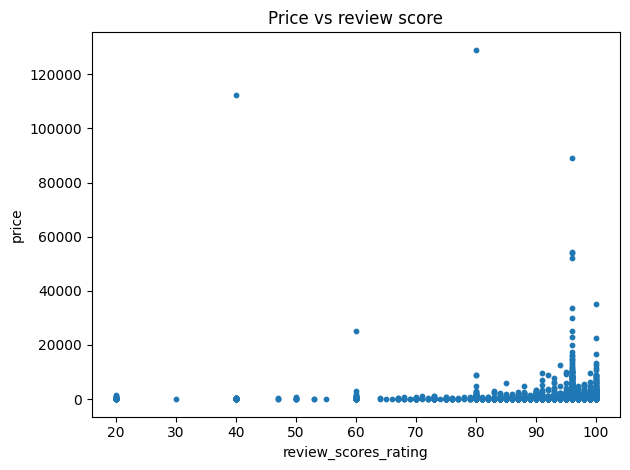

In [8]:
# price vs accommodates
df_plot = df_clean.sample(n=min(8000, len(df_clean)), random_state=0)

plt.figure()
plt.scatter(df_plot["accommodates"], df_plot["price"], s=10)
plt.title("Price vs accommodates")
plt.xlabel("accommodates")
plt.ylabel("price")
plt.tight_layout()
plt.show()


# price vs review_scores_rating
df_plot = df_clean.sample(n=min(8000, len(df_clean)), random_state=1)

plt.figure()
plt.scatter(df_plot["review_scores_rating"], df_plot["price"], s=10)
plt.title("Price vs review score")
plt.xlabel("review_scores_rating")
plt.ylabel("price")
plt.tight_layout()
plt.show()




The scatter plot between **price and review score** shows no strong relationship.
Prices vary widely even for highly rated listings indicating that a high review score
does not necessarily imply a higher price. Something we couldn't have assumed before looking deeper into the data.

In contrast the scatter plot between **price and accommodates** reveals a clearer pattern.
Listings that can host more people tend to be more expensive although there is still
significant variability within each group.

These observations suggest that accommodation size is more strongly related to price
than review scores.


### 4.5 Correlation matrix

We compute a correlation matrix for the numerical variables. This gives a quick overview of linear relationships between features.


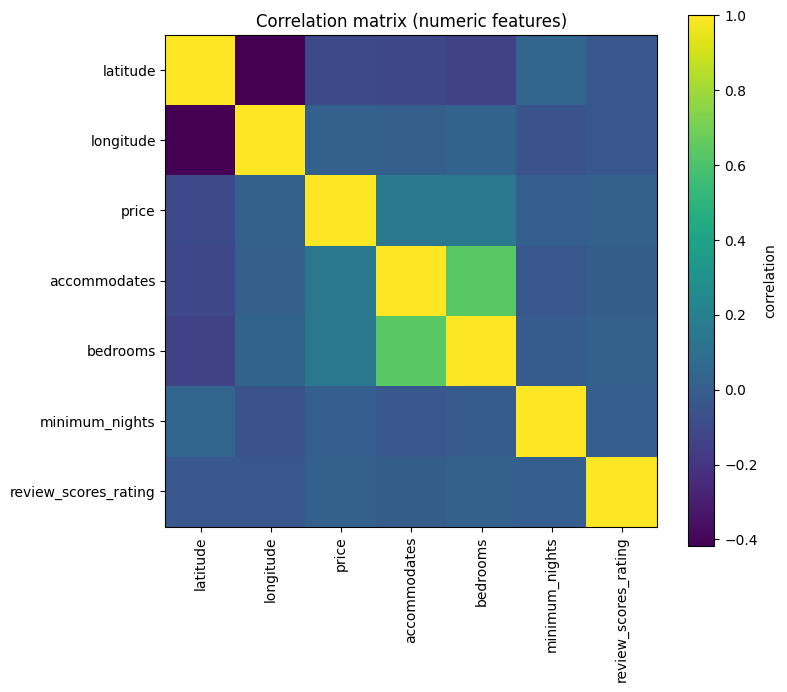

In [9]:
numeric_df = df_clean[["latitude", "longitude", "price", "accommodates", "bedrooms",
                       "minimum_nights", "review_scores_rating"]].copy()

corr = numeric_df.corr()

plt.figure(figsize=(8, 7))
plt.imshow(corr.values)
plt.title("Correlation matrix (numeric features)")
plt.colorbar(label="correlation")

plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)

plt.tight_layout()
plt.show()


### Correlation analysis

The first correlation matrix, computed using the full dataset, shows a strong positive
relationship between **accommodates** and **bedrooms** indicating that these two variables
describe similar aspects of accommodation size which seems logical.

However the relationship between **price** and size-related variables appears relatively
weak to moderate.
This is likely due to the presence of extreme price values which can distort linear
correlations and mask underlying patterns.

Other variables, such as **review scores** and **minimum nights**, show very low correlations
with price suggesting a limited linear relationship.
Geographical variables also display weak correlations with price indicating that location
effects are not captured by simple linear relationships.

### Motivation for removing price outliers

Given the highly skewed distribution of prices observed earlier extreme values may
disproportionately influence the correlation coefficients.
To verify whether the observed relationships are affected by these extreme values,
price outliers are removed before recomputing the correlation matrix.

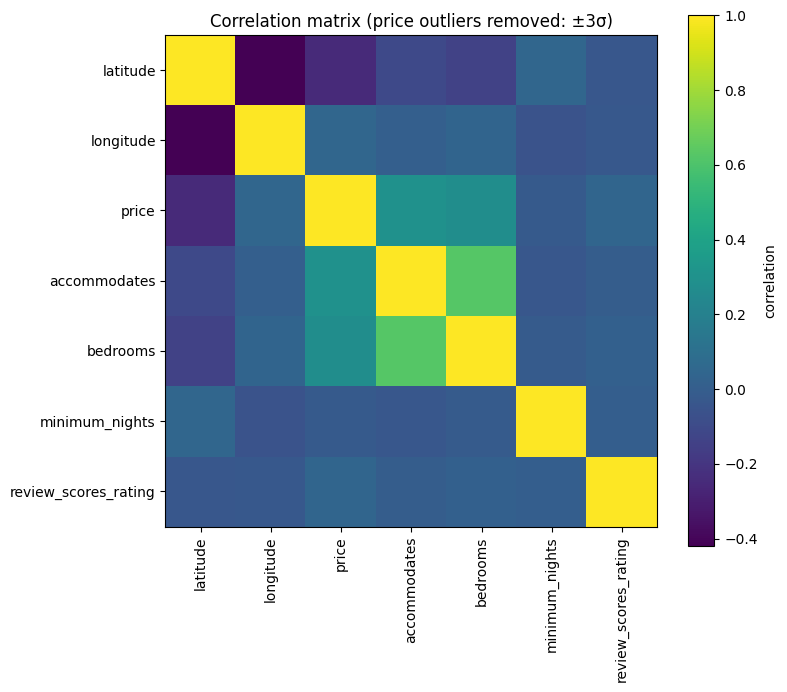

In [10]:
# Select numeric columns
numeric_df = df_clean[[
    "latitude", "longitude", "price",
    "accommodates", "bedrooms",
    "minimum_nights", "review_scores_rating"
]].copy()

# Remove price outliers: keep only values within mean ± 3*std
mean_price = numeric_df["price"].mean()
std_price = numeric_df["price"].std()

mask = (numeric_df["price"] >= mean_price - 3 * std_price) & (numeric_df["price"] <= mean_price + 3 * std_price)
numeric_df_no_outliers = numeric_df[mask].copy()

# Correlation matrix
corr = numeric_df_no_outliers.corr()

# Plot
plt.figure(figsize=(8, 7))
plt.imshow(corr.values)
plt.title("Correlation matrix (price outliers removed: ±3σ)")
plt.colorbar(label="correlation")

plt.xticks(range(len(corr.columns)), corr.columns, rotation=90)
plt.yticks(range(len(corr.columns)), corr.columns)

plt.tight_layout()
plt.show()


### Correlation analysis without price outliers

After removing extreme price values (beyond ±3 standard deviations) the correlation
structure becomes clearer and more interpretable.

In particular, **price** now shows a more pronounced positive correlation with
**accommodates** and **bedrooms** confirming that larger accommodations tend to be more
expensive.
This relationship was less visible in the presence of outliers.

The strong correlation between accommodates and bedrooms remains unchanged while
review scores and minimum nights continue to exhibit weak correlations with price.

Removing price outliers leads to more reliable conclusions and highlights the
importance of accommodation size in explaining price variations.

## 5) K-means clustering (from scratch)

In this section we follow the steps suggested in the course document.

1. Implement K-means using NumPy:
   - initialize centroids
   - compute squared Euclidean distances
   - assign points to the nearest centroid
   - update centroids as the mean of assigned points
   - stop when centroids do not move significantly (or after a maximum number of iterations)

2. Test the algorithm on a toy 2D dataset.

3. Apply the algorithm to a real dataset (and here to our Airbnb data).


In [11]:
def initialize_centroids(X, K, seed=0):
    # Randomly choose K points from the dataset as initial centroids
    np.random.seed(seed)
    indices = np.random.choice(len(X), K, replace=False)
    return X[indices].copy()

def squared_euclidean_distances(X, centroids):
    # Returns a (n_points, K) matrix of squared distances
    return np.sum((X[:, None, :] - centroids[None, :, :]) ** 2, axis=2)

def assign_clusters(X, centroids):
    distances = squared_euclidean_distances(X, centroids)
    labels = np.argmin(distances, axis=1)
    return labels

def update_centroids(X, labels, K, centroids):
    new_centroids = centroids.copy()
    for k in range(K):
        points_k = X[labels == k]
        if len(points_k) > 0:
            new_centroids[k] = points_k.mean(axis=0)
    return new_centroids

def kmeans_fit(X, K, max_iter=50, tol=1e-4, seed=0, return_history=False):
    centroids = initialize_centroids(X, K, seed=seed)

    history = []
    if return_history:
        history.append(centroids.copy())

    for _ in range(max_iter):
        labels = assign_clusters(X, centroids)
        new_centroids = update_centroids(X, labels, K, centroids)

        # stopping criterion: centroids do not move significantly
        shift = np.sqrt(np.sum((new_centroids - centroids) ** 2))
        centroids = new_centroids

        if return_history:
            history.append(centroids.copy())

        if shift < tol:
            break

    labels = assign_clusters(X, centroids)

    if return_history:
        return centroids, labels, history
    else:
        return centroids, labels




### 5.2) Toy dataset (2D)

We generate a simple 2D dataset:
- choose K "true" cluster centers randomly in 2D
- generate points around each center with a Gaussian distribution
- run our K-means algorithm
- visualize points and final centroids


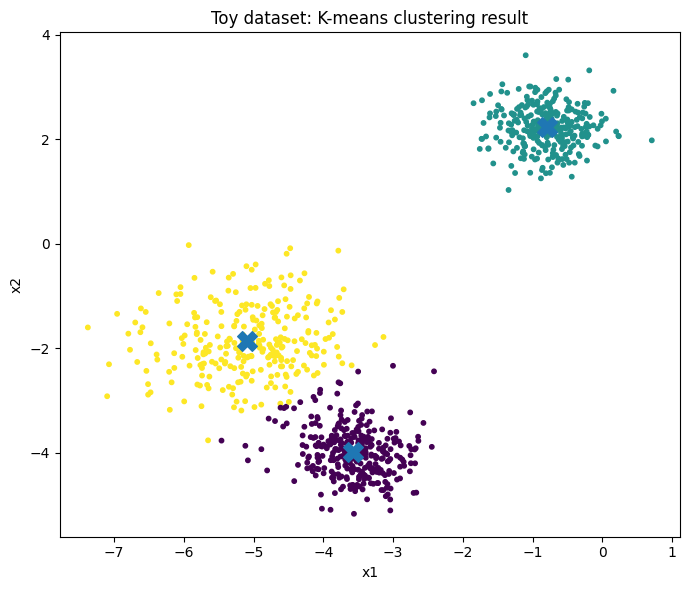

In [12]:
# Create a toy dataset in 2D
np.random.seed(1)

K_true = 3
points_per_cluster = 300

# Random true centers in 2D
true_centers = np.random.uniform(low=-5, high=5, size=(K_true, 2))

X_toy = []
for k in range(K_true):
    # Each cluster can have a different variance
    sigma = np.random.uniform(0.3, 1.0)
    cluster_points = true_centers[k] + np.random.normal(0, sigma, size=(points_per_cluster, 2))
    X_toy.append(cluster_points)

X_toy = np.vstack(X_toy)

# Run K-means on toy data
K = 3
centroids_toy, labels_toy = kmeans_fit(X_toy, K, max_iter=50, tol=1e-4, seed=0)

# Plot toy clustering results
plt.figure(figsize=(7, 6))
plt.scatter(X_toy[:, 0], X_toy[:, 1], c=labels_toy, s=10)
plt.scatter(centroids_toy[:, 0], centroids_toy[:, 1], marker="X", s=200)
plt.title("Toy dataset: K-means clustering result")
plt.xlabel("x1")
plt.ylabel("x2")
plt.tight_layout()
plt.show()


The toy dataset is composed of three well-separated groups of points in a two-dimensional space.
Each group is generated around a different center, with some random noise.

The K-means algorithm successfully identifies the three clusters.
Each cluster corresponds to one of the original groups of points and the centroids are located
near the center of each group.

This example illustrates how K-means works in a simple setting:
points are grouped according to their proximity to the centroids and the algorithm converges
towards stable cluster centers.
It also shows that K-means performs well when clusters are compact and well separated.


## 5.3 Apply K-means to the real dataset (Airbnb)

The exploratory data analysis shows that price is a central variable of interest
but its distribution is highly skewed and influenced by extreme values.
Scatter plots indicate that price is not strongly related to review scores
while a clearer relationship exists between price and accommodation size.

The correlation analysis confirms that price is moderately correlated with
variables describing the size of the accommodation whereas review scores and
minimum nights show weak correlations with price.
Geographical variables (latitude and longitude) do not exhibit strong linear
correlations with price but they remain essential to capture spatial structure.

Based on these observations, K-means clustering is applied using latitude,
longitude and price in order to identify geographical areas with similar price levels.
This choice allows the clustering to reflect both spatial proximity and economic
similarity while remaining consistent with the patterns observed in the data.


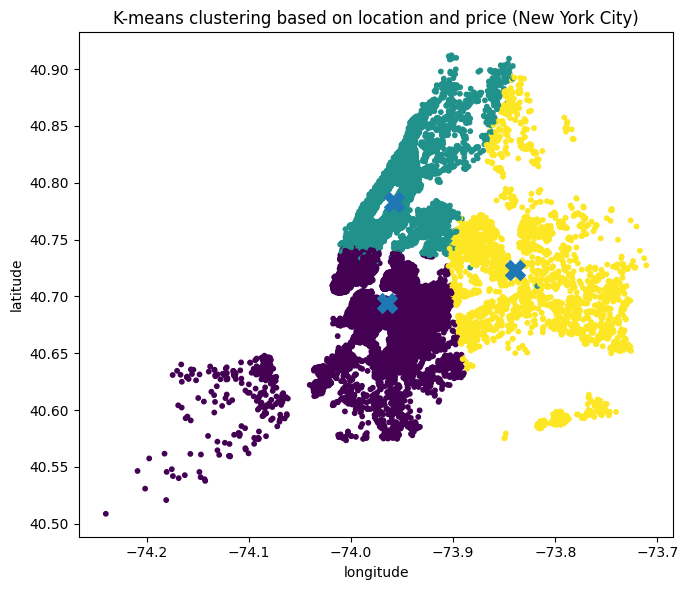

In [ ]:
df_nyc = df_clean[df_clean["city"] == "New York"].copy()

# K-means clustering based on location and price

# Variables used for clustering
features = ["latitude", "longitude", "price"]
X = df_nyc[features].values

# Normalize features (required for K-means)
X_mean = X.mean(axis=0)
X_std = X.std(axis=0)
X_std[X_std == 0] = 1.0
X_norm = (X - X_mean) / X_std

# Run K-means
K = 3
centroids, labels = kmeans_fit(X_norm, K, max_iter=60, tol=1e-4, seed=0)

# --- Plot clustering result ---

lat_i = features.index("latitude")
lon_i = features.index("longitude")

# Convert centroids back to original scale for better visualization
centroids_original = centroids * X_std + X_mean

plt.figure(figsize=(7, 6))
plt.scatter(X[:, lon_i], X[:, lat_i], c=labels, s=10)
plt.scatter(
    centroids_original[:, lon_i],
    centroids_original[:, lat_i],
    marker="X",
    s=200
)

plt.title("K-means clustering based on location and price (New York City)")
plt.xlabel("longitude")
plt.ylabel("latitude")
plt.tight_layout()
plt.show()

### Analysis of the K-means clustering

The clustering based on latitude, longitude, and price produces well-defined and
geographically coherent groups within New York City.
Each cluster corresponds to a distinct spatial area and the centroids are located
close to the center of these areas indicating a stable partition of the data.

K-means relies on Euclidean distances to assign observations to clusters.
As a consequence observations with extreme values and particularly very high prices can
have a strong influence on the position of the centroids and distort the cluster
boundaries.

For this reason it is important to verify whether the observed clustering structure
remains stable after removing price outliers.
This additional step allows us to ensure that the identified clusters reflect genuine
spatial and price patterns rather than being driven by a small number of extreme values.

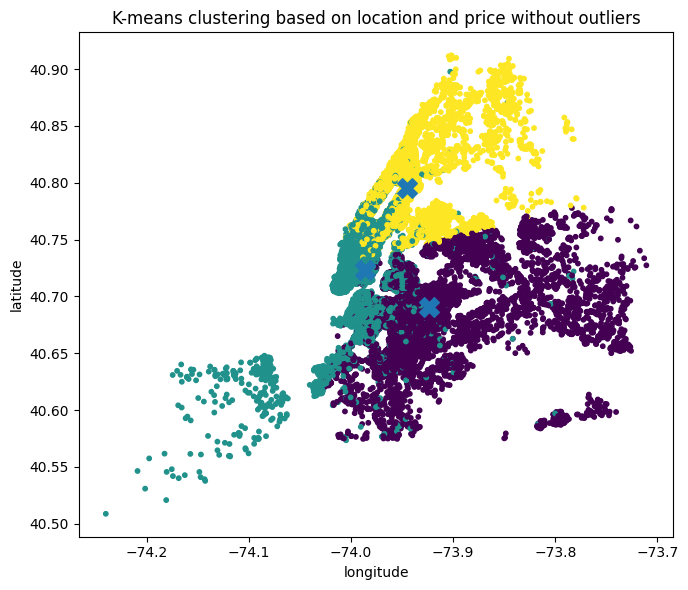

In [ ]:
df_nyc = df_clean[df_clean["city"] == "New York"].copy()

# Variables used for clustering
features = ["latitude", "longitude", "price"]

# Remove price outliers (mean ± 3*std)
price_mean = df_nyc["price"].mean()
price_std = df_nyc["price"].std()

mask = (
    (df_nyc["price"] >= price_mean - 3 * price_std) &
    (df_nyc["price"] <= price_mean + 3 * price_std)
)

df_nyc_no_outliers = df_nyc[mask].copy()

X = df_nyc_no_outliers[features].values

# Normalize features (required for K-means)
X_mean = X.mean(axis=0)
X_std = X.std(axis=0)
X_std[X_std == 0] = 1.0
X_norm = (X - X_mean) / X_std

# Run K-means
K = 3
centroids, labels = kmeans_fit(X_norm, K, max_iter=60, tol=1e-4, seed=0)

#Plot clusters using original coordinates

lat_i = features.index("latitude")
lon_i = features.index("longitude")

# Convert centroids back to original scale
centroids_original = centroids * X_std + X_mean

plt.figure(figsize=(7, 6))
plt.scatter(X[:, lon_i], X[:, lat_i], c=labels, s=10)
plt.scatter(
    centroids_original[:, lon_i],
    centroids_original[:, lat_i],
    marker="X",
    s=200
)

plt.title("K-means clustering based on location and price without outliers")
plt.xlabel("longitude")
plt.ylabel("latitude")
plt.tight_layout()
plt.show()

### Comparison of clustering results with and without price outliers

After removing price outliers the clustering remains geographically coherent.
However the clusters appear slightly less contrasted than in the clustering that
included all price values.

This observation suggests that in this dataset extreme price values may actually
carry meaningful information about spatial price differences rather than being pure noise.
By removing them some of the natural separation between high-price and lower-price
areas becomes less pronounced.

Since K-means relies on Euclidean distances price outliers influence the position of
the centroids and can accentuate differences between areas.
In this case keeping the outliers leads to clusters that better reflect the full
range of price variation across locations.

This comparison highlights a trade-off: removing outliers improves robustness,
while keeping them may preserve important economic signals.
Both results are informative and help better understand the structure of the data.


In [ ]:
df_k = pd.DataFrame(X, columns=features)
df_k["cluster"] = labels

df_k.groupby("cluster")[features].mean()


,latitude,longitude,price
cluster,,,
0,40.690471,-73.923869,78.863391
1,40.722994,-73.985981,207.927994
2,40.795306,-73.944848,91.017601



The average values show clear differences in price across clusters.
According to the clustering with outliers, cluster 0 corresponds to the purple area, cluster 1 to the yellow area,
and cluster 2 to the green area.
The yellow cluster is associated with the highest prices while the purple
cluster corresponds to the lowest-priced area.

### 6. Conclusion

In this project we conducted an exploratory analysis of an Airbnb listings dataset
to understand the main factors that characterize accommodation offers.
Through descriptive statistics and visualizations we identified patterns
in the data particularly the importance of accommodation size variables such as
**accommodates** and **bedrooms** in explaining price variations.

The correlation analysis showed that price is more strongly related to the size of
the accommodation than to review scores or minimum stay constraints.
We also observed that geographical variables do not exhibit simple linear
relationships with price motivating the use of clustering techniques.

To better understand spatial price patterns, we applied K-means clustering based on
latitude, longitude, and price focusing on New York City.
The resulting clusters revealed distinct geographical areas associated with different
price levels, highlighting meaningful spatial structures within the city.

Finally we compared clustering results with and without price outliers.
This comparison showed that while removing outliers improves robustness, keeping them
can preserve important information about high-price areas.